In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset


Load the dair_ai/emotion dataset from Hugging Face.https://huggingface.co/datasets/dair-ai/emotion

In [7]:
from IPython.utils.terminal import toggle_set_term_title
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label =emotion_dataset['train']['label']
test_text = emotion_dataset['test']['text']
test_label=emotion_dataset['test']['label']


README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [8]:
from datasets import load_dataset

emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']
test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']
label_name = emotion_dataset['train'].features['label'].names

df_train =pd.DataFrame(
    {
        'text':train_text,
        'label': [label_name[i] for i in train_label]

    }
)
df_test = pd.DataFrame({
    'text': test_text,
    'label':[label_name[i] for i in test_label]
})

In [9]:
df_train.isnull().sum()
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

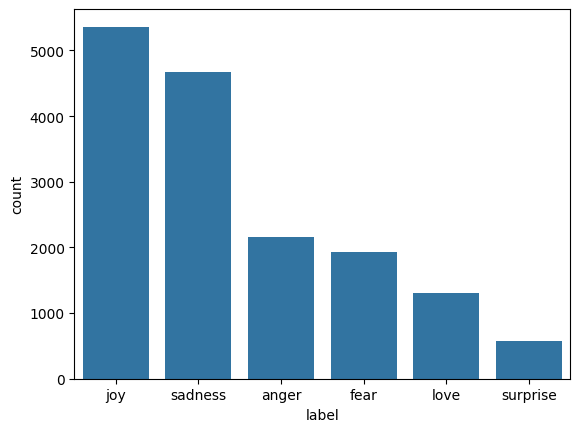

In [10]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)


In [11]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from datasets import load_dataset
import pandas as pd

# Re-defining variables from previous cells to ensure self-containment
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']
test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']
label_name = emotion_dataset['train'].features['label'].names

df_train =pd.DataFrame(
    {
        'text':train_text,
        'label': [label_name[i] for i in train_label]

    }
)
df_test = pd.DataFrame({
    'text': test_text,
    'label':[label_name[i] for i in test_label]
})

max_words=1000
tokenizer=Tokenizer(num_words=max_words,oov_token='<uk>')
tokenizer.fit_on_texts(df_train['text'])
train_sequence = tokenizer.texts_to_sequences(df_train['text'])#convert into zero
texts_sequence=tokenizer.texts_to_sequences(df_test['text'])
padded_train_sequence=pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')#for adding zero to extra space...padding
padded_texts_sequence=pad_sequences(texts_sequence,maxlen=50,padding='post',truncating='post')
padded_train_sequence
import numpy as np
train_labels=np.array(train_label)
test_labels =np.array(test_label)
num_classes=len(np.unique(train_labels))
print(f'Vocablulary size: {len(tokenizer.word_index)}')
print(f'Max Sentence Length: {padded_train_sequence.shape[1]}')

Vocablulary size: 15213
Max Sentence Length: 50


In [13]:
from sklearn.utils import class_weight
import numpy as np

class_weights=class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
class_weight_dict = dict(enumerate(class_weights))

In [14]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)


In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,LSTM,Dense,Dropout,SimpleRNN,GRU
rnn_model=Sequential([
      Embedding(input_dim = max_words,output_dim=128,input_length=50),
      SimpleRNN(units= 128, return_sequences=True),
      Dropout(0.5),
      SimpleRNN(units=64),
      Dropout(0.5),
      Dense(units=num_classes,activation='softmax'),



    ]
)
rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [16]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_texts_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
rnn_loss,rnn_accuracy=rnn_model.evaluate(padded_texts_sequence,test_labels)
print(f"RNN Test Loss: {rnn_loss}")
print(f"RNN Test Accuracy: {rnn_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 45ms/step - accuracy: 0.1659 - loss: 2.0888 - val_accuracy: 0.3490 - val_loss: 1.6942
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 42ms/step - accuracy: 0.1457 - loss: 1.8881 - val_accuracy: 0.3465 - val_loss: 1.7616
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.1301 - loss: 1.8247 - val_accuracy: 0.1375 - val_loss: 1.7834
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - accuracy: 0.1321 - loss: 1.8099 - val_accuracy: 0.2895 - val_loss: 1.7290
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3490 - loss: 1.6942
RNN Test Loss: 1.694223165512085
RNN Test Accuracy: 0.3490000069141388


LSTM

In [17]:
lstm_model=Sequential([
      Embedding(input_dim = max_words,output_dim=128,input_length=50),
      LSTM(units= 128, return_sequences=True),
      Dropout(0.5),
      LSTM(units=64),
      Dropout(0.5),
      Dense(units=num_classes,activation='softmax'),
  ])
lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])




lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_texts_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
lstm_loss,lstm_accuracy=lstm_model.evaluate(padded_texts_sequence,test_labels)
print(f"LSTM Test Loss: {lstm_loss}")
print(f"LSTM Test Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 125ms/step - accuracy: 0.1509 - loss: 1.7957 - val_accuracy: 0.0795 - val_loss: 1.8050
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 64s 128ms/step - accuracy: 0.1471 - loss: 1.7938 - val_accuracy: 0.1120 - val_loss: 1.7893
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 64s 127ms/step - accuracy: 0.1497 - loss: 1.7936 - val_accuracy: 0.1290 - val_loss: 1.8087
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.0795 - loss: 1.8050
LSTM Test Loss: 1.8050285577774048
LSTM Test Accuracy: 0.0794999971985817


GRU

In [18]:
gru_model=Sequential([
      Embedding(input_dim = max_words,output_dim=128,input_length=50),
      GRU(units= 128, return_sequences=True),
      Dropout(0.5),
      GRU(units=64),
      Dropout(0.5),
      Dense(units=num_classes,activation='softmax'),
  ])
gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])




gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_texts_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
gru_loss,gru_accuracy=gru_model.evaluate(padded_texts_sequence,test_labels)
print(f"GRU Test Loss: {gru_loss}")
print(f"GRU Test Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 61s 114ms/step - accuracy: 0.1405 - loss: 1.7966 - val_accuracy: 0.1375 - val_loss: 1.7780
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 79s 108ms/step - accuracy: 0.1634 - loss: 1.7952 - val_accuracy: 0.0795 - val_loss: 1.7809
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 111ms/step - accuracy: 0.1536 - loss: 1.7946 - val_accuracy: 0.3400 - val_loss: 1.7728
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.1375 - loss: 1.7780
GRU Test Loss: 1.7780125141143799
GRU Test Accuracy: 0.13750000298023224


In [19]:
result_df = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
     }).sort_values(by='Test Accuracy',ascending=False)

result_df

,Model,Test Loss,Test Accuracy
0,RNN,1.694223,0.3490
2,GRU,1.778013,0.1375
1,LSTM,1.805029,0.0795


In [20]:
from tensorflow.keras.layers import Bidirectional
BiGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])
BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
BiGRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_texts_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 159s 305ms/step - accuracy: 0.5673 - loss: 1.0992 - val_accuracy: 0.8415 - val_loss: 0.4639
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 209s 318ms/step - accuracy: 0.8604 - loss: 0.4047 - val_accuracy: 0.8635 - val_loss: 0.3775
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 195s 304ms/step - accuracy: 0.8767 - loss: 0.3249 - val_accuracy: 0.8705 - val_loss: 0.3230
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 152s 305ms/step - accuracy: 0.8842 - loss: 0.2985 - val_accuracy: 0.8655 - val_loss: 0.3690
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 208s 317ms/step - accuracy: 0.8909 - loss: 0.2770 - val_accuracy: 0.8645 - val_loss: 0.3942
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 161s 321ms/step - accuracy: 0.8978 - loss: 0.2561 - val_accuracy: 0.8690 - val_loss: 0.3644


In [22]:
BiGRU_loss,BiGRU_accuracy=BiGRU.evaluate(padded_texts_sequence,test_labels)
print(f"BiGRU Test Loss: {BiGRU_loss}")
print(f"BiGRU Test Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.8705 - loss: 0.3230
BiGRU Test Loss: 0.3230316638946533
BiGRU Test Accuracy: 0.8705000281333923


63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step


<Axes: >

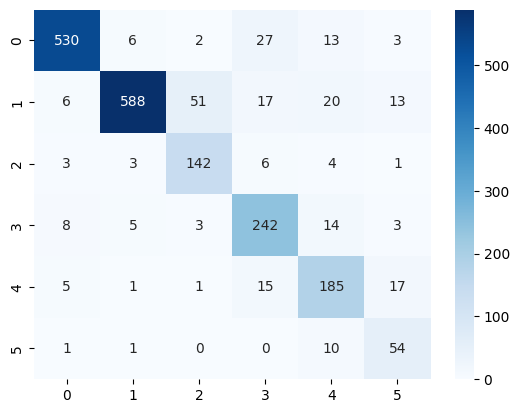

In [23]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions =np.argmax(BiGRU.predict(padded_texts_sequence),axis=1)
sns.heatmap(confusion_matrix(test_labels,BiGRU_predictions) , annot=True, fmt='d', cmap='Blues')


In [24]:
sample_texts = [
      "I can't believe how happy I am right now, this is amazing!",
    "I feel so calm and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift."
]
sample_sequences = tokenizer.texts_to_sequences(sample_texts)
padded_sample_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')
sample_predictions = np.argmax(BiGRU.predict(padded_sample_sequences), axis=1)
for i in range(len(sample_texts)):
    print(f"Text: {sample_texts[i]}\nPreduction Emotion: {label_name[sample_predictions[i]]}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
Text: I can't believe how happy I am right now, this is amazing!
Preduction Emotion: fear
Text: I feel so calm and hopeless today.
Preduction Emotion: joy
Text: I am furious that they cancelled the trip at the last minute.
Preduction Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Preduction Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift.
Preduction Emotion: surprise


In [31]:
import os
import pickle

model_dir='Artifacts'
os.makedirs(model_dir,exist_ok=True)# folder

#our bigru model
BiGRU.save(os.path.join(model_dir,'BiGRU.keras'))
with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file,protocol=pickle.HIGHEST_PROTOCOL)



In [26]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [27]:
label_name=emotion_dataset['train'].features['label'].names
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [28]:
 for i in train_label:
  print(label_name[i])

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr